In [2]:
# Path: /mnt/data/clean_image_script.py

import cv2
import hashlib
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import seaborn as sns
import sys
import time
import warnings
from PIL import Image
from imgaug import augmenters as iaa

warnings.filterwarnings("ignore")

In [3]:
# Configuration
IMAGE_DIRECTORY = "Dataset"
HASH_ALGORITHM = "md5"
CHUNK_SIZE = 4096
IMAGE_EXTENSION = ".jpg"


def calculate_file_hash(file_path, algorithm=HASH_ALGORITHM, chunk_size=CHUNK_SIZE):
    """Compute the hash of a file using the specified algorithm."""
    hash_object = hashlib.new(algorithm)
    with open(file_path, "rb") as file:
        while chunk := file.read(chunk_size):
            hash_object.update(chunk)
    return hash_object.hexdigest()


def find_and_remove_duplicates(directory, file_extension=IMAGE_EXTENSION):
    """Identify and remove duplicate image files based on file hashes."""
    hash_map = {}
    duplicates = []

    for root, _, files in os.walk(directory):
        for file_name in files:
            if file_name.lower().endswith(file_extension):
                file_path = os.path.join(root, file_name)
                file_hash = calculate_file_hash(file_path)

                if file_hash in hash_map:
                    duplicates.append(file_path)
                else:
                    hash_map[file_hash] = file_path

    for duplicate_path in duplicates:
        os.remove(duplicate_path)

    return len(duplicates)


if __name__ == "__main__":
    num_removed = find_and_remove_duplicates(IMAGE_DIRECTORY)
    print(f"Found and removed {num_removed} duplicate images.")

Found and removed 0 duplicate images.


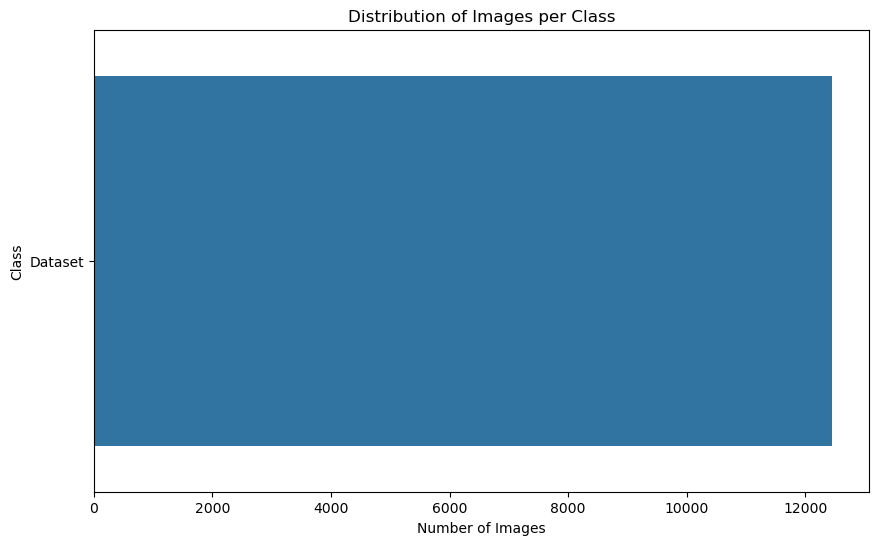

In [4]:
# Configuration
IMAGE_DIRECTORY = "Dataset"
OUTPUT_CSV = "dataset_cleaned.csv"
HASH_ALGORITHM = "md5"
CHUNK_SIZE = 4096

# Initialize variables
image_data = []
hashes = {}
duplicates = []

def calculate_image_hash(image_path, algorithm=HASH_ALGORITHM, chunk_size=CHUNK_SIZE):
    """Compute the hash of an image file using the specified algorithm."""
    hash_object = hashlib.new(algorithm)
    with open(image_path, "rb") as file:
        while chunk := file.read(chunk_size):
            hash_object.update(chunk)
    return hash_object.hexdigest()

for root, _, files in os.walk(IMAGE_DIRECTORY):
    label = os.path.basename(root)
    for file_name in files:
        if file_name.lower().endswith('.jpg'):
            image_path = os.path.join(root, file_name)
            file_hash = calculate_image_hash(image_path)

            if file_hash not in hashes:
                image_data.append({'filepath': image_path, 'label': label})
                hashes[file_hash] = image_path
            else:
                duplicates.append(image_path)

# Save the collected data in a Pandas DataFrame
df = pd.DataFrame(image_data)
df.to_csv(OUTPUT_CSV, index=False)

# Analyze and visualize the distribution of images per label
plt.figure(figsize=(10, 6))
sns.countplot(y='label', data=df, order=df['label'].value_counts().index)
plt.title('Distribution of Images per Class')
plt.xlabel('Number of Images')
plt.ylabel('Class')
plt.show()

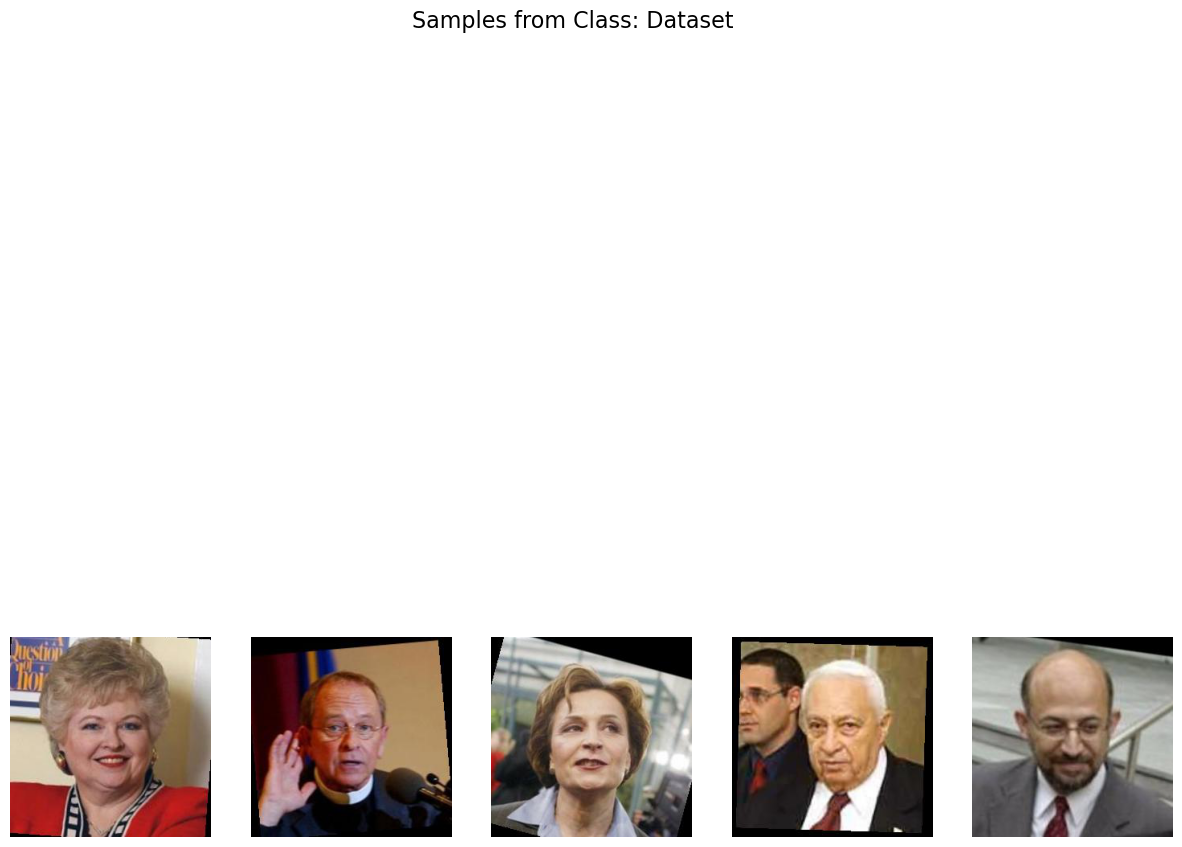

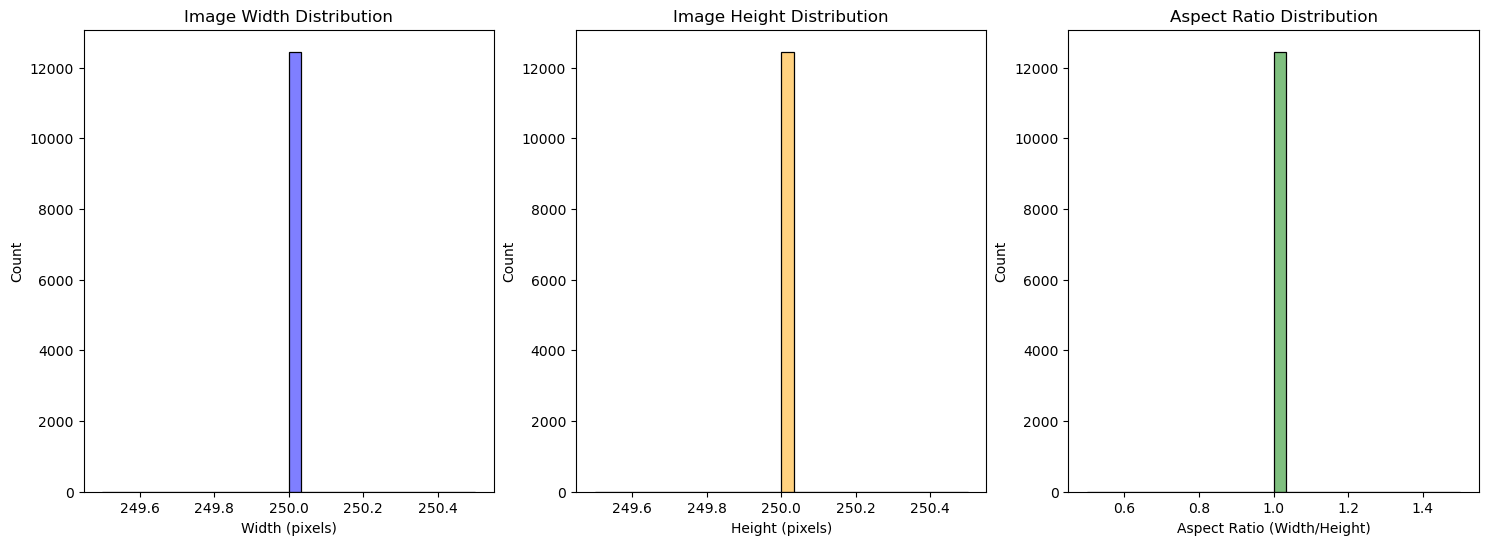

In [5]:
# Load the previously saved DataFrame with the cleaned dataset
df = pd.read_csv('dataset_cleaned.csv')

# Parameters
NUM_SAMPLES_PER_CLASS = 5

def show_samples_per_class(data_frame, num_samples):
    """Display sample images per class using matplotlib."""
    classes = data_frame['label'].unique()
    for cls in classes:
        cls_df = data_frame[data_frame['label'] == cls].sample(min(num_samples, len(cls_df := data_frame[data_frame['label'] == cls])))
        fig, axs = plt.subplots(1, len(cls_df), figsize=(15, 15))
        fig.suptitle(f'Samples from Class: {cls}', fontsize=16)
        for i, (_, row) in enumerate(cls_df.iterrows()):
            img = Image.open(row['filepath'])
            axs[i].imshow(img)
            axs[i].axis('off')
        plt.show()

show_samples_per_class(df, NUM_SAMPLES_PER_CLASS)

# Initialize lists for image dimensions and aspect ratios
widths, heights, aspect_ratios = [], [], []

# Analyze image dimensions and aspect ratios
for _, row in df.iterrows():
    img = Image.open(row['filepath'])
    width, height = img.size
    widths.append(width)
    heights.append(height)
    aspect_ratios.append(width / height)

# Plot histograms for image dimensions and aspect ratios
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

sns.histplot(widths, bins=30, kde=True, ax=axs[0], color='blue')
axs[0].set_title('Image Width Distribution')
axs[0].set_xlabel('Width (pixels)')

sns.histplot(heights, bins=30, kde=True, ax=axs[1], color='orange')
axs[1].set_title('Image Height Distribution')
axs[1].set_xlabel('Height (pixels)')

sns.histplot(aspect_ratios, bins=30, kde=True, ax=axs[2], color='green')
axs[2].set_title('Aspect Ratio Distribution')
axs[2].set_xlabel('Aspect Ratio (Width/Height)')

plt.show()

In [6]:
# Load the cleaned dataset
df = pd.read_csv('dataset_cleaned.csv')

# Initialize lists to store image dimensions
widths, heights = [], []

# Collect all image dimensions
for _, row in df.iterrows():
    img = Image.open(row['filepath'])
    width, height = img.size
    widths.append(width)
    heights.append(height)

def detect_outliers(values):
    """Detect outliers using the Interquartile Range (IQR) method."""
    q1, q3 = np.percentile(values, [25, 75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return lower_bound, upper_bound

# Calculate the IQR bounds for image dimensions
width_lower, width_upper = detect_outliers(widths)
height_lower, height_upper = detect_outliers(heights)

# Filter out rows with image dimensions outside the IQR bounds
filtered_df = df[(np.array(widths) >= width_lower) & (np.array(widths) <= width_upper) &
                 (np.array(heights) >= height_lower) & (np.array(heights) <= height_upper)]

print(f"Removed {len(df) - len(filtered_df)} images due to outlier dimensions.")

# Define augmentation strategies
augmentor = iaa.Sequential([
    iaa.Fliplr(0.5),
    iaa.Flipud(0.2),
    iaa.Affine(rotate=(-30, 30)),
    iaa.AddToHueAndSaturation((-20, 20)),
    iaa.Crop(percent=(0, 0.1))
])

# Directory and data setup
OUTPUT_DIRECTORY = 'AugmentedDataset'
os.makedirs(OUTPUT_DIRECTORY, exist_ok=True)
augmented_data = []

# Apply augmentations and save the new images
for label in filtered_df['label'].unique():
    class_samples = filtered_df[filtered_df['label'] == label]
    num_to_augment = max(100, class_samples.shape[0])

    for _, row in class_samples.iterrows():
        img = Image.open(row['filepath'])
        img_np = np.array(img)
        augmented_images = augmentor(images=[img_np] * (num_to_augment // class_samples.shape[0]))

        for idx, aug_img in enumerate(augmented_images):
            aug_img_pil = Image.fromarray(aug_img)
            file_path = os.path.join(OUTPUT_DIRECTORY, f"{label}_{idx}.jpg")
            aug_img_pil.save(file_path)
            augmented_data.append({'filepath': file_path, 'label': label})

# Create a DataFrame with the augmented dataset
augmented_df = pd.DataFrame(augmented_data)
augmented_df.to_csv('balanced_augmented_dataset.csv', index=False)

Removed 0 images due to outlier dimensions.


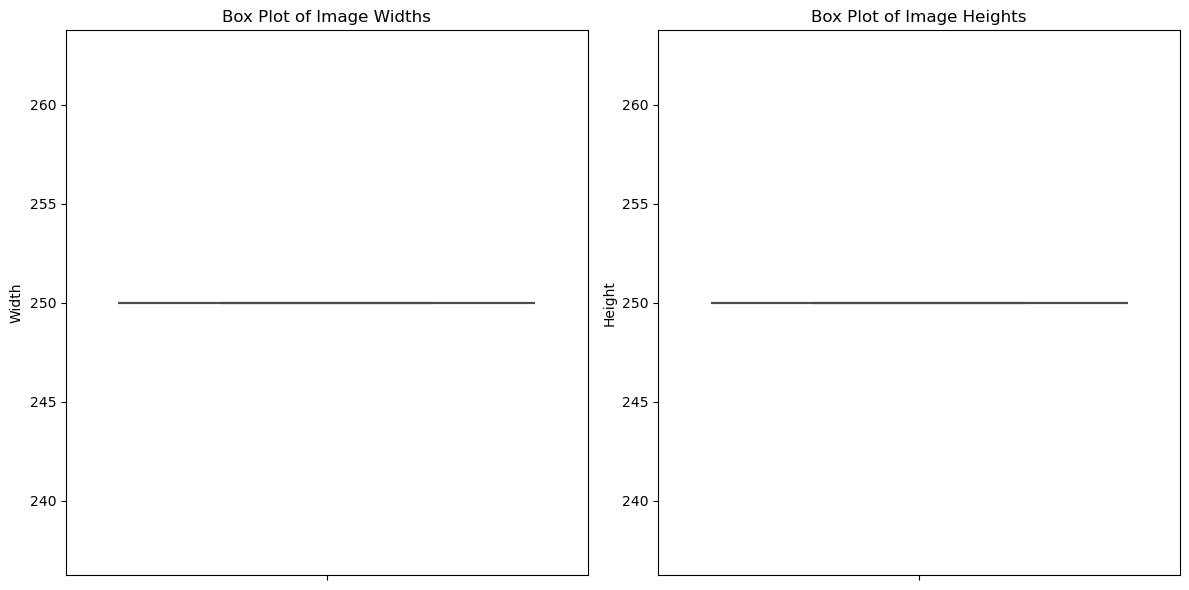

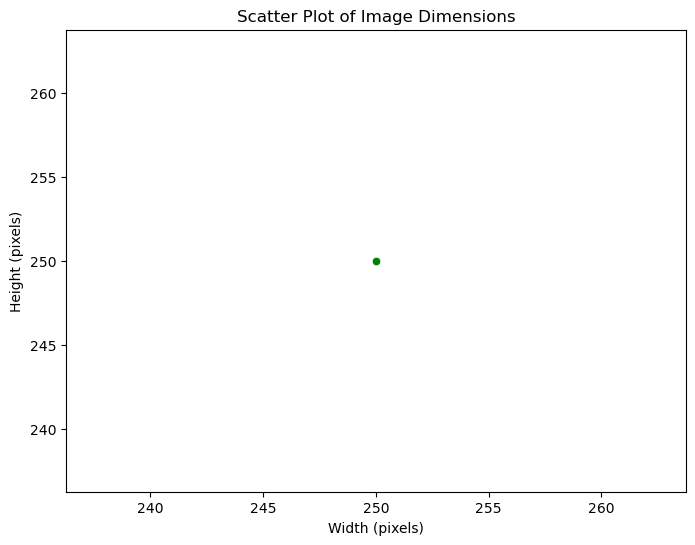

In [13]:
# Load the cleaned dataset with image dimensions if not already loaded
# (replace this with your dataset loading code)
df = pd.read_csv('dataset_cleaned.csv')

# Initialize lists to store image dimensions
widths = []
heights = []

# Collect all image dimensions
for _, row in df.iterrows():
    img = Image.open(row['filepath'])
    width, height = img.size
    widths.append(width)
    heights.append(height)

# Convert dimensions to a DataFrame for visualization
dimension_df = pd.DataFrame({'Width': widths, 'Height': heights})

# Create Box Plots to visualize outliers
plt.figure(figsize=(12, 6))

# Box plot for Width
plt.subplot(1, 2, 1)
sns.boxplot(y='Width', data=dimension_df, color='blue')
plt.title('Box Plot of Image Widths')

# Box plot for Height
plt.subplot(1, 2, 2)
sns.boxplot(y='Height', data=dimension_df, color='orange')
plt.title('Box Plot of Image Heights')

plt.tight_layout()
plt.show()

# Scatter plot to visualize widths vs. heights
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Width', y='Height', data=dimension_df, marker='o', color='green')
plt.title('Scatter Plot of Image Dimensions')
plt.xlabel('Width (pixels)')
plt.ylabel('Height (pixels)')
plt.show()